In [1]:
import scanpy as sc
adata_sc = sc.read("./h5ad/adata_sc.h5ad")

In [48]:
H_poor = ["H-nS01","H-nS09","H-nS10"]
H_good = ["H-nS03","H-nS06","H-nS07","H-nS08"]
Q_poor = ["Q-nS01","Q-nS02"]
Q_good = ["Q-nS03","Q-nS04"]

In [54]:
sc.write("./h5ad/H_poor.h5ad",adata_sc[adata_sc.obs["batch"].isin(H_poor)])
sc.write("./h5ad/Q_poor.h5ad",adata_sc[adata_sc.obs["batch"].isin(Q_poor)])
sc.write("./h5ad/H_good.h5ad",adata_sc[adata_sc.obs["batch"].isin(H_good)])
sc.write("./h5ad/Q_good.h5ad",adata_sc[adata_sc.obs["batch"].isin(Q_good)])

In [2]:
import cellphonedb as cpd
from cellphonedb.src.core.methods import cpdb_statistical_analysis_method
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import ktplotspy as kpy
import os

for name in ['H_poor', 'H_good', 'Q_poor', 'Q_good']:
    adata = sc.read('./h5ad/' + name + ".h5ad", var_names='gene_symbols')

    # Remove rows with gene IDs starting with 'ENSG'
    adata = adata[:, ~adata.var_names.str.startswith('ENSG')]

    # Prepare required input files
    # Raw count matrix
    counts_df = pd.DataFrame(adata.X.T.todense(), index=adata.var_names, columns=adata.obs_names)
    counts_df.to_csv('counts_matrix.csv')

    # Metadata file (requires cell type annotation in adata.obs['type'])
    meta_data = pd.DataFrame({'Cell': adata.obs_names, 'cell_type': adata.obs['type']})
    meta_data.to_csv('meta_data.csv', index=False)

    # Run CellPhoneDB
    cpdb_results = cpdb_statistical_analysis_method.call(
        meta_file_path='meta_data.csv',
        counts_file_path='counts_matrix.csv',
        cpdb_file_path='cellphonedb.zip',
        counts_data='hgnc_symbol',
        output_path="./res",
        subsampling=False,
        score_interactions=True,
    )

    means_df = cpdb_results['means']
    means_df.to_csv("./table/" + name + '_mean.csv', index=False)

    means_sig_df = cpdb_results['significant_means']
    means_sig_df.to_csv("./table/" + name + '_significant_means.csv', index=False)

Reading user files...
The following user files were loaded successfully:
counts_matrix.csv
meta_data.csv
[ ][CORE][24/10/26-13:31:05][INFO] [Cluster Statistical Analysis] Threshold:0.1 Iterations:1000 Debug-seed:-1 Threads:4 Precision:3
[ ][CORE][24/10/26-13:31:09][INFO] Running Real Analysis
[ ][CORE][24/10/26-13:31:09][INFO] Running Statistical Analysis


100%|███████████████████████████████████████████████████████████████████████████████| 1000/1000 [05:40<00:00,  2.94it/s]


[ ][CORE][24/10/26-13:36:50][INFO] Building Pvalues result
[ ][CORE][24/10/26-13:36:50][INFO] Building results
[ ][CORE][24/10/26-13:36:51][INFO] Scoring interactions: Filtering genes per cell type..


100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 21.76it/s]

[ ][CORE][24/10/26-13:36:51][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..


...

[ ][CORE][24/10/26-14:44:42][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..



100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 58.75it/s]


[ ][CORE][24/10/26-14:44:43][INFO] Scoring interactions: Calculating scores for all interactions and cell types..


100%|█████████████████████████████████████████████████████████████████████████████████| 100/100 [00:21<00:00,  4.61it/s]


Saved deconvoluted to ./res/statistical_analysis_deconvoluted_10_24_2026_144507.txt
Saved deconvoluted_percents to ./res/statistical_analysis_deconvoluted_percents_10_24_2026_144507.txt
Saved means to ./res/statistical_analysis_means_10_24_2026_144507.txt
Saved pvalues to ./res/statistical_analysis_pvalues_10_24_2026_144507.txt
Saved significant_means to ./res/statistical_analysis_significant_means_10_24_2026_144507.txt
Saved interaction_scores to ./res/statistical_analysis_interaction_scores_10_24_2026_144507.txt


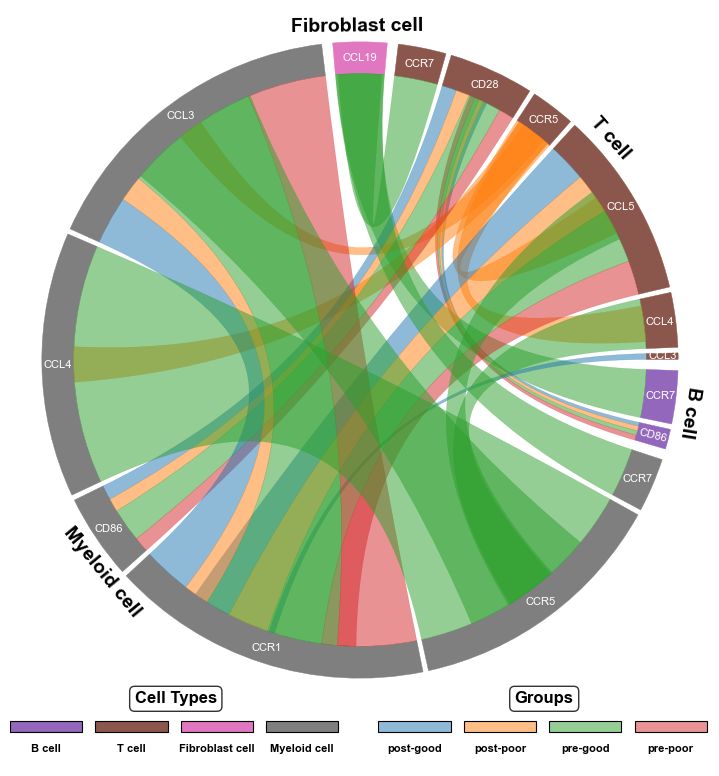

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path
import matplotlib.patches as patches
import pandas as pd

# Keep original chord diagram plotting utility functions
LW = 0.3

def polar2xy(r, theta):
    return np.array([r*np.cos(theta), r*np.sin(theta)])

def hex2rgb(c):
    return tuple(int(c[i:i+2], 16)/256.0 for i in (1, 3 ,5))

def IdeogramArc(start=0, end=60, radius=1.0, width=0.2, ax=None, color=(1,0,0)):
    if start > end:
        start, end = end, start
    start *= np.pi/180.
    end *= np.pi/180.
    opt = 4./3. * np.tan((end-start)/ 4.) * radius
    inner = radius*(1-width)
    verts = [
        polar2xy(radius, start),
        polar2xy(radius, start) + polar2xy(opt, start+0.5*np.pi),
        polar2xy(radius, end) + polar2xy(opt, end-0.5*np.pi),
        polar2xy(radius, end),
        polar2xy(inner, end),
        polar2xy(inner, end) + polar2xy(opt*(1-width), end-0.5*np.pi),
        polar2xy(inner, start) + polar2xy(opt*(1-width), start+0.5*np.pi),
        polar2xy(inner, start),
        polar2xy(radius, start),
    ]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]

    if ax is None:
        return verts, codes
    else:
        path = Path(verts, codes)
        patch = patches.PathPatch(path, facecolor=color+(1.0,), edgecolor=color+(1.0,), lw=LW)
        ax.add_patch(patch)


def ChordArc(start1=0, end1=60, start2=180, end2=240, radius=1.0, chordwidth=0.7, ax=None, color=(1,0,0)):
    if start1 > end1:
        start1, end1 = end1, start1
    if start2 > end2:
        start2, end2 = end2, start2
    start1 *= np.pi/180.
    end1 *= np.pi/180.
    start2 *= np.pi/180.
    end2 *= np.pi/180.
    opt1 = 4./3. * np.tan((end1-start1)/ 4.) * radius
    opt2 = 4./3. * np.tan((end2-start2)/ 4.) * radius
    rchord = radius * (1-chordwidth)
    verts = [
        polar2xy(radius, start1),
        polar2xy(radius, start1) + polar2xy(opt1, start1+0.5*np.pi),
        polar2xy(radius, end1) + polar2xy(opt1, end1-0.5*np.pi),
        polar2xy(radius, end1),
        polar2xy(rchord, end1),
        polar2xy(rchord, start2),
        polar2xy(radius, start2),
        polar2xy(radius, start2) + polar2xy(opt2, start2+0.5*np.pi),
        polar2xy(radius, end2) + polar2xy(opt2, end2-0.5*np.pi),
        polar2xy(radius, end2),
        polar2xy(rchord, end2),
        polar2xy(rchord, start1),
        polar2xy(radius, start1),
    ]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CURVE4, Path.CURVE4, Path.CURVE4]
 
    if ax is None:
        return verts, codes
    else:
        path = Path(verts, codes)
        patch = patches.PathPatch(path, facecolor=color+(0.5,), edgecolor=color+(0.4,), lw=LW)
        ax.add_patch(patch)


def selfChordArc(start=0, end=60, radius=1.0, chordwidth=0.7, ax=None, color=(1,0,0)):
    if start > end:
        start, end = end, start
    start *= np.pi/180.
    end *= np.pi/180.
    opt = 4./3. * np.tan((end-start)/ 4.) * radius
    rchord = radius * (1-chordwidth)
    verts = [
        polar2xy(radius, start),
        polar2xy(radius, start) + polar2xy(opt, start+0.5*np.pi),
        polar2xy(radius, end) + polar2xy(opt, end-0.5*np.pi),
        polar2xy(radius, end),
        polar2xy(rchord, end),
        polar2xy(rchord, start),
        polar2xy(radius, start),
    ]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]

    if ax is None:
        return verts, codes
    else:
        path = Path(verts, codes)
        patch = patches.PathPatch(path, facecolor=color+(0.5,), edgecolor=color+(0.4,), lw=LW)
        ax.add_patch(patch)

def chordDiagram(X, ax, colors=None, width=0.1, pad=1, chordwidth=0.7,outer_labels = None,inner_labels=None,groups=None):
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)

    if colors is None:
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
                  '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
        colors = [hex2rgb(colors[i]) for i in range(len(colors))]

    
    a_dim, b_dim, c_dim, d_dim, e_dim = X.shape
    X = X.transpose(0, 2, 1, 3, 4)
    X = X.reshape(a_dim * c_dim, b_dim * d_dim, e_dim)
    group_X = X.copy()
    
    X = np.sum(X,axis=2)
    x = np.maximum(np.max(X,axis=0),np.max(X,axis=1))

    y = (x / np.sum(x).astype(float)) * (360 - pad * len(x) - pad * len(outer_labels) + pad * sum(x==0))
    arc = []
    start = -16.25
    for i in range(len(x)):
        if y[i]==0:
            arc.append((start, start))
            if i%len(inner_labels) == len(inner_labels) - 1:
                start += pad
            continue
        end = start + y[i]
        arc.append((start, end))
        start = end + pad
        if i%len(inner_labels) == len(inner_labels) - 1:
            start += pad
    
    for i in range(len(x)):
        start1, end1 = arc[i]
        if start1==end1:
            continue
        IdeogramArc(start=start1, end=end1, radius=1.0, ax=ax, color=colors[(i//len(inner_labels))+4], width=width)
        factor = (1 - X[i,i]/x[i])/2
        s1, e1 = start1 + factor*(end1 - start1) , end1 - factor*(end1 - start1)
        if sum(group_X[i,i])!=0:
            ratios_tp = group_X[i,i]/sum(group_X[i,i])
            ratios = [0]
            for k in range(len(ratios_tp)):
                ratios.append(sum(ratios_tp[:k+1]))
            for k,r in enumerate(ratios[1:]):
                if r ==ratios[k]:
                    gs1 = s1 + (e1-s1)*ratios[k]
                    ge1 = s1 + (e1-s1)*r
                    gs2 = s1 + (e1-s1)*(1-r)
                    ge2 = s1 + (e1-s1)*(1-ratios[k])
                    if gs2 == ge1:
                        selfChordArc(gs1, ge2, radius=1. - width, color=colors[k], chordwidth=chordwidth * 0.7, ax=ax)
                    else:
                        ChordArc(gs1, ge1, gs2, ge2, radius=1. - width, color=colors[k], chordwidth=chordwidth, ax=ax)
        
        for j in range(i):
            start2, end2 = arc[j]
            if start2==end2:
                continue
            if x[j]!=0:
                factor1 = (1 - X[i,j]/x[i])/2
                factor2 = (1 - X[i,j]/x[j])/2
                s1, e1 = start1 + factor1*(end1 - start1) , end1 - factor1*(end1 - start1)
                s2, e2 = start2 + factor2*(end2 - start2) , end2 - factor2*(end2 - start2)
                if sum(group_X[i,j])!=0:
                    ratios_tp = group_X[i,j]/sum(group_X[i,j])
                    ratios = [0]
                    for k in range(len(ratios_tp)):
                        ratios.append(sum(ratios_tp[:k+1]))
                    for k,r in enumerate(ratios[1:]):
                        if r ==ratios[k]:
                            continue
                        gs1 = s1 + (e1-s1)*ratios[k]
                        ge1 = s1 + (e1-s1)*r
                        gs2 = s2 + (e2-s2)*(1-r)
                        ge2 = s2 + (e2-s2)*(1-ratios[k])
                        ChordArc(gs1, ge1, gs2, ge2, radius=1. - width, color=colors[k], chordwidth=chordwidth, ax=ax)
                factor1 = (1 - X[j,i]/x[i])/2
                factor2 = (1 - X[j,i]/x[j])/2
                s1, e1 = start1 + factor1*(end1 - start1) , end1 - factor1*(end1 - start1)
                s2, e2 = start2 + factor2*(end2 - start2) , end2 - factor2*(end2 - start2)
                if sum(group_X[j,i])!=0:
                    ratios_tp = group_X[j,i]/sum(group_X[j,i])
                    ratios = [0]
                    for k in range(len(ratios_tp)):
                        ratios.append(sum(ratios_tp[:k+1]))
                    for k,r in enumerate(ratios[1:]):
                        if r ==ratios[k]:
                            continue
                        gs1 = s1 + (e1-s1)*ratios[k]
                        ge1 = s1 + (e1-s1)*r
                        gs2 = s2 + (e2-s2)*(1-r)
                        ge2 = s2 + (e2-s2)*(1-ratios[k])
                        ChordArc(gs1, ge1, gs2, ge2, radius=1. - width, color=colors[k], chordwidth=chordwidth, ax=ax)

            
    # Add inner and outer labels at the end of the function
    if inner_labels is not None:
        # Draw inner ring labels
        inner_radius = 0.95  # Move outward slightly
        for i in range(len(x)):
            # Get the current outer ring node angle range
            start_angle, end_angle = arc[i]
            if start_angle==end_angle:
                continue
            center_angle = (start_angle + end_angle) / 2
            angle_rad = center_angle * np.pi / 180
            x = inner_radius * np.cos(angle_rad)
            y = inner_radius * np.sin(angle_rad)
            if i == 3:
                ax.text(x, y, inner_labels[i%len(inner_labels)], ha='center', va='center', fontsize=8,color="w",rotation=center_angle)
            else:
                ax.text(x, y, inner_labels[i%len(inner_labels)], ha='center', va='center', fontsize=8,color="w")
            
    # Draw outer ring cell type labels
    if outer_labels is not None:
        outer_radius = 1.05  # Outer ring label radius, slightly outside the arc
        n_cells = len(outer_labels)
        
        # Calculate total angle range for each cell type
        cell_angles = []
        for i in  range(len(outer_labels)):
            cell_angles.append((arc[i*len(inner_labels)][0],arc[i*len(inner_labels)+len(inner_labels)-1][1]))
        
        # Draw outer ring cell type labels
        for i in range(n_cells):
            if i < len(cell_angles):
                start_angle, end_angle = cell_angles[i]
                center_angle = (start_angle + end_angle) / 2
                angle_rad = center_angle * np.pi / 180
                x_pos = outer_radius * np.cos(angle_rad)
                y_pos = outer_radius * np.sin(angle_rad)
                
                # Calculate label rotation angle for horizontal readability
                label_angle = center_angle
                if -30 <= label_angle <= 210:
                    label_angle -= 90
                else:
                    label_angle -= 270
                
                ax.text(x_pos, y_pos, outer_labels[i].capitalize(), 
                       ha='center', va='center', 
                       fontsize=14, rotation=label_angle,
                       weight="heavy")

    #return nodePos

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def add_legends(fig, ax, cell_colors, cell_labels, group_colors, group_labels):
    """
    Add two legends at the bottom of the figure with improved aesthetics and spacing
    """
    # Set global font
    plt.rcParams['font.family'] = 'Arial'
    plt.rcParams['font.size'] = 8

    # ==========================
    # Legend area settings: shifted down, taller, and wider
    # ==========================
    left_legend_ax = fig.add_axes([0.0, -0.07, 0.45, 0.07])  # y=0.005 shifted down, height=0.07 taller
    left_legend_ax.set_xlim(0, 1)
    left_legend_ax.set_ylim(0, 1)
    left_legend_ax.axis('off')

    right_legend_ax = fig.add_axes([0.50, -0.07, 0.45, 0.07])
    right_legend_ax.set_xlim(0, 1)
    right_legend_ax.set_ylim(0, 1)
    right_legend_ax.axis('off')

    # ==========================
    # Draw cell type legend (layered layout)
    # ==========================
    n_cells = len(cell_labels)
    total_width = 0.99
    spacing = 0.04  # Horizontal spacing
    box_width = (total_width - (n_cells - 1) * spacing) / n_cells

    # Layout: title at top -> color blocks in middle -> text at bottom
    title_y = 1.2
    color_y = 0.6
    text_y = 0.3

    for i, (color, label) in enumerate(zip(cell_colors, cell_labels)):
        x_pos =   i * (box_width + spacing)

        # Color square (top)
        rect = patches.Rectangle((x_pos, color_y), box_width, 0.2,
                                 facecolor=color, edgecolor='black', linewidth=0.8)
        left_legend_ax.add_patch(rect)

        # Text label (bottom)
        text_x = x_pos + box_width / 2
        left_legend_ax.text(text_x, text_y, label.capitalize(), ha='center', va='center',
                            fontsize=8, weight='bold', wrap=True)

    # Title (top)
    left_legend_ax.text(0.5, title_y, 'Cell Types', ha='center', va='center',
                        fontsize=12, weight='bold', color='black',
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.8))

    # ==========================
    # Draw group legend
    # ==========================
    n_groups = len(group_labels)
    box_width = (total_width - (n_groups - 1) * spacing) / n_groups

    for i, (color, label) in enumerate(zip(group_colors, group_labels)):
        x_pos =  i * (box_width + spacing)

        rect = patches.Rectangle((x_pos, color_y), box_width, 0.2,
                              facecolor=(*color, 0.5),  # Note: *color unpacks RGB tuple and appends alpha
                              edgecolor='black',
                              linewidth=0.8)
        right_legend_ax.add_patch(rect)

        text_x = x_pos + box_width / 2
        right_legend_ax.text(text_x, text_y, label, ha='center', va='center',
                             fontsize=8, weight='bold', wrap=True)

    # Title
    right_legend_ax.text(0.5, title_y, 'Groups', ha='center', va='center',
                         fontsize=12, weight='bold', color='black',
                         bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.8))
 

if __name__ == "__main__":
    # 1. Define categories and correlation matrix
    cells = ['B cell', 'T cell', 'Stromal cell', 'Myeloid cell']
    cells_display = [c.replace('Stromal cell', 'Fibroblast cell') for c in cells]
    genes = ["CCL3","CCL4","CCL5","CD86","CCL19","CCR1","CCR5","CD28","CCR7"]
    groups = ["post-good","post-poor","pre-good","pre-poor"]
    files = ["H-good","H-poor","Q-good","Q-poor"]
    
    correlationMatrix = np.zeros((len(cells),len(cells),len(genes),len(genes),len(groups)))

    for a in range(len(cells)):
        for b in range(len(cells)):
            for c in range(len(genes)):
                for d in range(len(genes)):
                    for e in range(len(groups)):
                        df = pd.read_csv('./table/'+files[e].replace("-","_")+'_significant_means.csv')
                        row = df[df['interacting_pair'] == genes[c]+"_"+genes[d]]
                        if len(row)==1:
                            if not np.isnan(row.iloc[0][cells[a]+"|"+cells[b]]):
                                correlationMatrix[a,b,c,d,e] = row.iloc[0][cells[a]+"|"+cells[b]]

    
    # Create figure and main axes
    fig = plt.figure(figsize=(7/0.95, 8)) # Increase figure height to leave space for legends
    ax = plt.axes([0.0, 0.0, 0.95, 0.875]) # [left, bottom, width, height] Adjust bottom and height
    
    # Plot chord diagram
    # nodePos = 
    chordDiagram(
        correlationMatrix, 
        ax, 
        colors=None,
        width=0.1,
        pad=1,
        chordwidth=0.7,
        inner_labels=genes,
        outer_labels=cells_display,
        groups = groups
    )

    # 3. Chart styling and annotations
    ax.axis('off')
    
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
                  '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    colors = [hex2rgb(colors[i]) for i in range(len(colors))]
    cell_colors = [colors[4+i] for i in range(len(cells))]
    group_colors = [colors[i] for i in range(len(groups))]
    
    add_legends(fig, ax, cell_colors, cells_display, group_colors,groups)
    
    # Save image
    plt.tight_layout()
    plt.show()